# 1. Preparación del notebook

## Instalación de paqueterías y descarga de base de datos

Con la siguiente línea descargamos las paqueterias en su versión necesaria. Después las importamos.

In [32]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement matplotlib.pyplot (from versions: none)

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for matplotlib.pyplot


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Ahora leemos la base de datos desde el repositorio.

In [34]:
# Cargar base de datos
url = (
    "https://github.com/serpennskill/"
    "Proyecto_equipo_9/releases/download/"
    "Dataset/listings.csv"
)
# Configurar formato de visualización de números
pd.options.display.float_format = '{:,.2f}'.format
df = pd.read_csv(url, low_memory=False)
df.head(5)

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,281134,https://www.airbnb.com/rooms/281134,20260923225035,2026-09-25,NaN,COOL PENT HOUSE APARTMENT @CONDESA,Amazing Pent House apartment in the heart fo C...,NaN,https://a0.muscache.com/pictures/5754595/e5ec9...,196253,...,5.00,5.00,4.86,NaN,NaN,10,4,3,0,0.05
1,35797,https://www.airbnb.com/rooms/35797,20260923225035,2026-09-25,NaN,Villa,"Dentro de Villa un estudio de arte con futon, ...",NaN,https://a0.muscache.com/pictures/f395ab78-1185...,153786,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
2,44616,https://www.airbnb.com/rooms/44616,20260923225035,2026-09-25,NaN,Condesa Haus,A new concept of hosting in mexico through a b...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,196253,...,4.79,4.98,4.45,NaN,NaN,10,4,3,0,0.37
3,56074,https://www.airbnb.com/rooms/56074,20260923225035,2026-09-24,NaN,Great space in historical San Rafael,This great apartment is located in one of the ...,NaN,https://a0.muscache.com/pictures/3005118/60dac...,265650,...,4.94,4.76,4.79,NaN,NaN,1,1,0,0,0.45
4,66055,https://www.airbnb.com/rooms/66055,20260923225035,2026-09-26,NaN,Private Room+Bath 10 min Walk to World Cup Sta...,"Private room with your own en-suite bathroom, ...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,323211,...,5.00,4.00,5.00,NaN,NaN,1,0,1,0,0.01


In [35]:
#Como parte de la limpieza de datos posterior, eliminaremos las columnas con valores nulos en todas sus columnas
df = df.dropna(axis=1, how='all')
print(f" Columnas resultantes después de la limpieza: {df.shape[1]}")

 Columnas resultantes después de la limpieza: 75


# 2. Exploración y estadística descriptiva

En esta sección se realizará un análisis exploratorio del conjunto de datos con el propósito de identificar sus características principales y obtener información que permita responder las preguntas de investigación planteadas.

Se utilizarán medidas de tendencia central, dispersión y posición, así como tablas de frecuencias y comparaciones entre grupos. El análisis se enfocará principalmente en la distribución geográfica de los alojamientos, sus precios, características, anfitriones y calificaciones.

### 2.1 Distribución geográfica de los alojamientos

Se analizará la distribución de los anuncios entre las distintas alcaldías de la Ciudad de México. También se examinará la frecuencia de los tipos de habitación disponibles para identificar cuáles tienen mayor presencia en el conjunto de datos.

In [36]:
# Frecuencia de alojamientos por alcaldía
frecuencia_alcaldia = df['neighbourhood_cleansed'].value_counts()

frecuencia_alcaldia

neighbourhood_cleansed
Cuauhtémoc                14166
Miguel Hidalgo             4739
Benito Juárez              3474
Coyoacán                   2209
Venustiano Carranza        1103
Tlalpan                    1011
Álvaro Obregón             1000
Gustavo A. Madero           577
Iztacalco                   577
Azcapotzalco                411
Cuajimalpa de Morelos       403
Iztapalapa                  380
Xochimilco                  210
La Magdalena Contreras      137
Tláhuac                      46
Milpa Alta                   25
Name: count, dtype: int64

In [37]:
# Frecuencia de alojamientos por tipo de habitación
frecuencia_habitacion = df['room_type'].value_counts()

frecuencia_habitacion

room_type
Entire home/apt    20348
Private room        9770
Shared room          275
Hotel room            75
Name: count, dtype: int64

In [38]:
# Distribución de tipos de habitación por alcaldía
distribucion_alcaldia = pd.crosstab(
    df['neighbourhood_cleansed'],
    df['room_type']
)

distribucion_alcaldia

room_type,Entire home/apt,Hotel room,Private room,Shared room
neighbourhood_cleansed,,,,
Azcapotzalco,268,0,141,2
Benito Juárez,2043,5,1414,12
Coyoacán,1124,3,1075,7
Cuajimalpa de Morelos,284,0,119,0
Cuauhtémoc,10401,50,3522,193
Gustavo A. Madero,308,0,260,9
Iztacalco,350,0,223,4
Iztapalapa,208,0,167,5
La Magdalena Contreras,65,0,70,2


**Interpretación:**

La distribución de los alojamientos muestra una concentración importante en determinadas alcaldías de la Ciudad de México. Cuauhtémoc destaca con aproximadamente el 46.6 % de los anuncios, seguida de Miguel Hidalgo y Benito Juárez. En conjunto, estas tres alcaldías concentran cerca del 73.5 % de los registros.

Respecto al tipo de habitación, predominan los alojamientos completos, que representan aproximadamente el 66.5 % del total, mientras que las habitaciones privadas constituyen el 32.1 %. Las habitaciones compartidas y de hotel tienen una participación considerablemente menor.

La tabla cruzada confirma que Cuauhtémoc concentra la mayor cantidad de anuncios, tanto de alojamientos completos como de habitaciones privadas. Estos resultados muestran que la oferta registrada en Airbnb presenta una distribución geográfica desigual y una marcada preferencia por los alojamientos completos.

Es importante señalar que estos resultados describen la distribución de los anuncios registrados, pero no permiten determinar por sí solos la demanda turística ni la ocupación de los alojamientos.

### 2.2 Análisis descriptivo de los precios

Se analizará el comportamiento de los precios por noche de los alojamientos mediante medidas de tendencia central, dispersión y posición. Posteriormente, se compararán los precios según la alcaldía y el tipo de habitación para identificar posibles diferencias entre estos grupos.

In [39]:
# Tipo de dato y primeros valores de la variable precio
df['price'].dtype, df['price'].head(10)

(<StringDtype(storage='python', na_value=nan)>,
 0     $3,505.00
 1     $8,874.00
 2    $21,950.00
 3       $605.00
 4     $3,095.00
 5     $2,183.00
 6     $1,397.76
 7     $1,491.33
 8     $4,561.73
 9       $617.00
 Name: price, dtype: str)

In [40]:
# Convertir precios a valores numéricos
precio_num = pd.to_numeric(
    df['price'].str.replace('$', '', regex=False)
               .str.replace(',', '', regex=False),
    errors='coerce'
)

# Verificar los resultados
precio_num.head(10)

0    3,505.00
1    8,874.00
2   21,950.00
3      605.00
4    3,095.00
5    2,183.00
6    1,397.76
7    1,491.33
8    4,561.73
9      617.00
Name: price, dtype: float64

In [41]:
# Estadística descriptiva de los precios
precio_num.describe()

count      28,360.00
mean        2,339.92
std        14,094.18
min           136.80
25%           942.20
50%         1,500.00
75%         2,326.62
max     1,826,199.19
Name: price, dtype: float64

**Interpretación:**

El análisis descriptivo muestra una diferencia entre la media 2,339.92 MXN y la mediana 1,500.00 MXN, lo que sugiere una distribución asimétrica hacia la derecha, posiblemente influenciada por alojamientos con precios elevados.

El 50 % central de los anuncios presenta precios entre 942.20 y 2,326.63 MXN por noche. Asimismo, la desviación estándar de 14,094.18 MXN refleja una elevada dispersión. Destaca el precio máximo registrado de 1,826,199.00 MXN, que podría representar un valor atípico y será considerado para su revisión en el apartado de calidad y limpieza.

Finalmente, se identificaron 28,360 registros con precios válidos, equivalentes aproximadamente al 93.1 % del conjunto de datos.

In [42]:
# Estadística descriptiva de los precios por tipo de habitación
df.assign(precio_num=precio_num).groupby('room_type')['precio_num'].describe()

,count,mean,std,min,25%,50%,75%,max
room_type,,,,,,,,
Entire home/apt,"18,975.00","2,729.04","8,146.42",138.81,"1,322.57","1,828.00","2,696.89","790,057.15"
Hotel room,74.00,"4,612.05","4,904.04",291.00,"1,321.00","2,300.00","7,439.25","23,142.00"
Private room,"9,057.00","1,553.87","21,948.59",136.80,606.94,849.00,"1,250.00","1,826,199.19"
Shared room,254.00,636.99,935.99,168.00,280.25,400.00,700.00,"8,859.20"


**Interpretación:**

La comparación por tipo de habitación muestra diferencias en los precios de los alojamientos. Las habitaciones de hotel presentan la media más elevada, con 4,612.05 MXN por noche, mientras que los alojamientos completos tienen una mediana de 1,828.00 MXN. Por otro lado, las habitaciones privadas y compartidas registran medianas de 849.00 y 400.00 MXN, respectivamente.

Se observa una elevada dispersión en los precios de las habitaciones privadas, cuya desviación estándar alcanza 21,948.59 MXN. Este comportamiento está posiblemente relacionado con la presencia de valores extremos, particularmente por el precio máximo registrado de 1,826,199.19 MXN.

En general, las medias son superiores a las medianas en los cuatro grupos, lo que sugiere distribuciones asimétricas hacia la derecha. Por ello, la mediana resulta una medida especialmente útil para comparar los precios habituales entre los distintos tipos de habitación.

### 2.2.2 Comparación de precios por alcaldía

Se compararán los precios de los alojamientos entre las distintas alcaldías de la Ciudad de México, utilizando medidas descriptivas para identificar diferencias en los precios según su ubicación.

In [43]:
# Estadística descriptiva de los precios por alcaldía
df.assign(precio_num=precio_num).groupby(
    'neighbourhood_cleansed'
)['precio_num'].describe().sort_values(
    '50%', ascending=False
)

,count,mean,std,min,25%,50%,75%,max
neighbourhood_cleansed,,,,,,,,
Miguel Hidalgo,"4,374.00","2,887.27","12,826.80",224.00,"1,234.50","1,880.01","2,982.74","790,057.15"
Cuajimalpa de Morelos,364.00,"2,610.12","5,127.73",252.00,"1,164.00","1,797.00","2,455.12","78,000.00"
Cuauhtémoc,"13,226.00","2,592.29","16,959.99",164.80,"1,150.00","1,700.00","2,533.90","1,826,199.19"
Álvaro Obregón,918.00,"1,905.01","2,883.46",160.00,849.00,"1,340.86","1,935.00","36,299.00"
Coyoacán,"2,057.00","1,906.31","3,502.79",237.41,785.67,"1,200.00","1,915.00","91,140.00"
Benito Juárez,"3,203.00","1,682.70","2,611.79",192.00,799.00,"1,200.00","1,817.95","58,546.00"
Iztacalco,559.00,"1,316.74",833.14,136.80,762.50,"1,159.00","1,696.00","7,377.00"
Xochimilco,188.00,"1,870.54","2,304.93",138.81,659.75,"1,044.40","1,995.15","12,887.00"
Tlalpan,945.00,"3,481.13","33,045.29",158.05,650.00,"1,020.00","2,166.67","1,000,300.00"


**Interpretación:**

La comparación de precios por alcaldía muestra diferencias importantes en los valores de los alojamientos. Miguel Hidalgo presenta la mediana más elevada, con 1,880.00 MXN por noche, seguida de Cuajimalpa de Morelos, con 1,797.00 MXN, y Cuauhtémoc, con 1,700.00 MXN.

Por otra parte, Tlalpan registra la media más alta, con 3,481.13 MXN, aunque su mediana es de apenas 1,020.00 MXN. Esta diferencia sugiere la presencia de precios considerablemente elevados que afectan el promedio.

También se observa una elevada dispersión en los precios de algunas alcaldías, particularmente en Tlalpan, Cuauhtémoc y Miguel Hidalgo.

En general, los resultados muestran que los precios varían entre alcaldías y que la mediana permite realizar comparaciones menos sensibles a los valores extremos que la media.

### 2.3 Relación entre el precio y las características de los alojamientos

Se analizará la relación entre el precio por noche y algunas características numéricas de los alojamientos, particularmente la capacidad de huéspedes, el número de habitaciones y el número de camas. Para ello, se utilizará la correlación de Pearson, con el propósito de identificar posibles asociaciones entre estas variables.

In [44]:
# Correlación entre precio y características de los alojamientos
variables_correlacion = df.assign(precio_num=precio_num)[
    ['precio_num', 'accommodates', 'bedrooms', 'beds']
]

correlacion = variables_correlacion.corr(method='pearson')

correlacion

,precio_num,accommodates,bedrooms,beds
precio_num,1.00,0.10,0.11,0.09
accommodates,0.10,1.00,0.71,0.78
bedrooms,0.11,0.71,1.00,0.75
beds,0.09,0.78,0.75,1.00


**Interpretación:**

La matriz de correlaciones muestra que el precio presenta asociaciones lineales positivas muy débiles con la capacidad de huéspedes (0.10), el número de habitaciones (0.11) y el número de camas (0.09). Esto indica que, de manera individual, estas características no presentan una relación lineal importante con el precio dentro del conjunto de datos analizado.

Por otra parte, se observan correlaciones positivas más elevadas entre la capacidad de huéspedes y el número de habitaciones (0.71), la capacidad y el número de camas (0.78), así como entre habitaciones y camas (0.75). Esto sugiere que estas características físicas están relacionadas entre sí.

En general, los resultados muestran que las características de capacidad y distribución física de los alojamientos presentan asociaciones entre ellas, mientras que su relación lineal individual con el precio es débil. Es importante considerar que la correlación de Pearson únicamente mide asociaciones lineales y no implica causalidad.

# 3. Calidad, limpieza y transformación


El objetivo de esta etapa es transformar el conjunto de datos crudo en un dataframe limpio, estructurado y estadísticamente robusto. Esto se logrará mediante una reducción de dimensionalidad, tratamiento de valores nulos o atípicos, ajuste de fomratos y posibles transformaciones. Al finalizar esta sección, los datos estarán listos para un análisis exploratorio preciso y sin sesgos de extracción.

Para garantizar la eficiencia computacional y la viabilidad del análisis, se llevó a cabo un proceso de reducción de dimensionalidad sobre el conjunto de datos original, pasando de 90 variables a un subconjunto específico que responde directamente a las preguntas de investigación. Para la elección de estas variables se consideraron los siguientes criterios:

- Conservamos las columnas id y host_id para no perder de vista a qué anuncio y a qué anfitrión pertenece cada registro.

- Se retienen variables booleanas clave (host_is_superhost, host_identity_verified, host_has_profile_pic) y operativas (host_listings_count), ya que el nivel de profesionalización y la confianza transmitida por el anfitrión son factores altamente correlacionados con el precio y la demanda.

- Se seleccionan métricas financieras (price), operativas (minimum_nights, availability_365) y características físicas de la propiedad (room_type, accommodates, bathrooms_text) que dictan la naturaleza del servicio.

- En lugar de usar todas las sub-calificaciones de las reseñas (que suelen ser repetitivas, ya que si a un huésped le gusta el lugar, suele ponerle 5 estrellas a todo), nos quedamos únicamente con la calificación general (review_scores_rating). Por otro lado, para medir qué tan activo es el anuncio, conservamos tanto el total de reseñas (number_of_reviews), que nos dice cuánta experiencia y confianza histórica tiene el lugar, como las reseñas por mes (reviews_per_month). Como esta última variable divide el total de reseñas entre los meses de vida del anuncio (de acuerdo a la descripción del diccionario), nos sirve para estimar la ocupación real. Esto le ayuda al modelo a distinguir fácilmente entre lugares que son muy viejos pero se rentan poco, y lugares nuevos que son súper populares.

Por el contrario, se tomó la decisión de descartar el resto de las variables debido a que aportan ruido analítico, redundancia estadística o sesgos de extracción:

- Se descartaron métricas repetitivas de disponibilidad (ej. availability_30, 60, 90) en favor de la métrica anual (365) para evitar problemas de multicolinealidad. Lo mismo aplicó para las sub-calificaciones de reseñas.

- Se eliminaron todas las variables del tipo price_quote_... y calculated_.... Estos campos muestran precios o cálculos capturados en el día exacto en que se descargaron los datos (scraping). Si la extracción coincidió con un fin de semana o un día festivo, esos precios estarán inflados y no reflejarán la tarifa base o "normal" del alojamiento. Quedarnos únicamente con la variable original price nos asegura trabajar con el valor real sin que el modelo se confunda por picos de demanda de un día en específico.

- Dejamos fuera los enlaces (URLs), los nombres de los alojamientos y las descripciones extensas que escriben los anfitriones, ya que su manipulación puede requerir técnicas más avanzadas y además son variables que no aportan mayor valor para los fines de este proyecto, por lo que es mucho más eficiente enfocarnos en los datos numéricos y las características físicas que sí impactan directamente en el precio.

Antes de proceder a la imputación de datos faltantes,se aplicarán algunos filtros para asegurar la calidad de la estructura restante. Se descartarán de manera automática los campos que contengan un 100% de valores nulos (lo cual se realizó al inicio en la carga del dataset) y se evaluará si existen registros duplicados o campos idénticos que deban ser eliminados.

In [45]:
# Lista de campos seleccionados para el analisis
campos_seleccionados = [
    'id', 'host_id',
    'host_is_superhost', 'host_identity_verified', 'host_has_profile_pic', 'host_listings_count',
    'neighbourhood_cleansed', 'latitude', 'longitude',
    'property_type', 'room_type', 'accommodates', 'bedrooms', 'beds', 'bathrooms_text',
    'price', 'minimum_nights', 'availability_365',
    'number_of_reviews', 'review_scores_rating', 'reviews_per_month'
]

# Filtramos quedándonos solo con nuestras columnas seleccionadas
cols_presentes = [col for col in campos_seleccionados if col in df.columns]
df_reducido = df[cols_presentes].copy()
print(f"Columnas finales seleccionadas: {len(df_reducido.columns)}")

# Diagnóstico de valores nulos a tratar (ahora sí, sobre el reducido)
print("\n--- PORCENTAJE DE NULOS A TRATAR ---")
porcentaje_nulos = (df_reducido.isnull().mean() * 100).round(2)
print(porcentaje_nulos[porcentaje_nulos > 0].sort_values(ascending=False))

Columnas finales seleccionadas: 21

--- PORCENTAJE DE NULOS A TRATAR ---
review_scores_rating   13.40
reviews_per_month      13.40
price                   6.92
beds                    1.41
bathrooms_text          0.12
bedrooms                0.08
dtype: float64


Tras realizar el diagnóstico de valores nulos en nuestras 21 variables clave, se identificaron tres escenarios que requieren estrategias de limpieza distintas:

La variable principal (price - 6.92% nulos): Dado que el precio es la métrica central (variable objetivo) de nuestro análisis, imputar estos datos usando promedios o medianas generaría una varianza artificial y un sesgo grave en los resultados estadísticos. Además, al representar únicamente el 6.92% del total de los datos, la eliminación de estas filas se encuentra dentro del umbral de tolerancia aceptable (< 10%), lo que nos permite descartarlas sin comprometer la representatividad estadística ni la robustez de la muestra.

Listados sin interacciones (review_scores_rating y reviews_per_month — 13.40 % nulos): La coincidencia en el porcentaje de valores faltantes sugiere anuncios nuevos o sin historial de reseñas. Para reviews_per_month, imputar 0 es coherente con la ausencia de reseñas mensuales; en cambio, dado que review_scores_rating opera en una escala de 1 a 5, asignar 0 introduciría un valor fuera de dominio que sesgaría promedios y dispersión a la baja. Por ello, review_scores_rating se conserva como nulo (NaN) para analizarse únicamente sobre alojamientos evaluados, y se crea la variable indicadora tiene_resenas (1 con reseñas, 0 sin reseñas) para identificar y comparar ambos grupos.

Características físicas incompletas (beds, bedrooms, bathrooms_text - < 1.5% nulos): Al ser un porcentaje estadísticamente muy bajo, se optó por rellenar los huecos para no perder el resto de la información de esas filas. Las variables numéricas (beds y bedrooms) se imputaron utilizando la mediana (para evitar el sesgo de valores atípicos), mientras que la variable categórica (bathrooms_text) se rellenó con la moda (el tipo de baño más frecuente).


In [46]:
# Eliminamos los registros que no tienen precio
df_reducido_2 = df_reducido.dropna(subset=['price']).copy()

# Creamos la variable indicadora antes de imputar reviews_per_month
# 1 = tiene calificación registrada (escala 1-5), 0 = sin reseñas / sin calificación
df_reducido_2['tiene_resenas'] = df_reducido_2['review_scores_rating'].notna().astype(int)

# Creamos un diccionario con las reglas de imputación para las demás variables
# Nota: review_scores_rating se conserva como NaN para no introducir un 0 fuera de escala (1-5)
valores_imputacion = {
    'beds': df_reducido_2['beds'].median(),
    'bedrooms': df_reducido_2['bedrooms'].median(),
    'bathrooms_text': df_reducido_2['bathrooms_text'].mode()[0],
    'reviews_per_month': 0,
}

# Aplicamos la imputación a todo el dataframe
df_reducido_2 = df_reducido_2.fillna(value=valores_imputacion)

# Verificamos nulos: se espera que únicamente review_scores_rating conserve NaN en registros sin reseñas
print("--- COMPROBACIÓN DE NULOS TRAS IMPUTACIÓN ---")
nulos_por_columna = df_reducido_2.isnull().sum()
nulos_esperados_rating = nulos_por_columna.get('review_scores_rating', 0)
otros_nulos = nulos_por_columna.drop(labels=['review_scores_rating'], errors='ignore')
otros_nulos = otros_nulos[otros_nulos > 0]

if len(otros_nulos) == 0:
    print(
        f"Sin nulos en el resto de variables. Filas conservadas: {len(df_reducido_2)} "
        f"de {len(df)} originales."
    )
    print(
        f"Registros con review_scores_rating (1-5): {df_reducido_2['tiene_resenas'].sum()} | "
        f"Sin reseñas (NaN conservados): {nulos_esperados_rating}"
    )
else:
    print(f"Aún quedan nulos en otras columnas:\n{otros_nulos}")

--- COMPROBACIÓN DE NULOS TRAS IMPUTACIÓN ---
Aún quedan nulos en otras columnas:
minimum_nights    1
dtype: int64


Al realizar la comprobación de calidad, el código detectó 1 valor nulo aislado en la columna minimum_nights. Dado que es un solo registro entre miles, representaba una proporción tan minúscula (< 0.01%) que no fue visible durante el diagnóstico inicial de porcentajes. Para no desechar la fila entera por un solo campo faltante, procederemos a imputar este valor residual utilizando la mediana de la columna.

In [47]:
# Imputamos el valor nulo residual con la mediana de noches mínimas
df_reducido_2['minimum_nights'] = df_reducido_2['minimum_nights'].fillna(df_reducido_2['minimum_nights'].median())

# Verificamos que el dataframe haya quedado libre de nulos
print("--- COMPROBACIÓN FINAL DE NULOS ---")
df_sin_rating = df_reducido_2.drop(columns=['review_scores_rating'])
nulos_restantes = df_sin_rating.isnull().sum().sum()

if nulos_restantes == 0:
    print(f"El dataframe está limpio (conservando únicamente los nulos esperados en 'review_scores_rating'). Nos quedamos con {len(df_reducido_2)} filas de las {len(df)} originales.")
else:
    nulos_por_col = df_sin_rating.isnull().sum()
    print(f"Aún quedan nulos inesperados. Revisa las siguientes columnas:\n{nulos_por_col[nulos_por_col > 0]}")

--- COMPROBACIÓN FINAL DE NULOS ---
El dataframe está limpio (conservando únicamente los nulos esperados en 'review_scores_rating'). Nos quedamos con 28360 filas de las 30468 originales.


Únicamente nos quedamos con los valores nulos en la variable review_scores_rating, ya que como se mencionó anteriormente, dicha variable se encuentra en una escala del 1 al 5, por lo que los valores nulos simplemente representan un alojamiento sin reseña.

In [48]:
# Observamos el tipo de dato de algunas de nuestras variables de interés
print(df_reducido_2[['price', 'host_is_superhost', 'bathrooms_text']].head())
print("\n--- TIPOS DE DATOS ACTUALES ---")
print(df_reducido_2[['price', 'host_is_superhost', 'bathrooms_text']].dtypes)
print("\n--- VALORES ÚNICOS EN bathrooms_text ---")
print(df_reducido_2['bathrooms_text'].unique())

        price host_is_superhost  bathrooms_text
0   $3,505.00                 t  1 private bath
1   $8,874.00                 f  1 private bath
2  $21,950.00                 t       5.5 baths
3     $605.00                 f          1 bath
4   $3,095.00                 f         3 baths

--- TIPOS DE DATOS ACTUALES ---
price                str
host_is_superhost    str
bathrooms_text       str
dtype: object

--- VALORES ÚNICOS EN bathrooms_text ---
<StringArray>
[   '1 private bath',         '5.5 baths',            '1 bath',
           '3 baths',           '5 baths',         '4.5 baths',
           '2 baths',     '1 shared bath',  '1.5 shared baths',
         '1.5 baths',    '2 shared baths',         '3.5 baths',
           '0 baths',  '2.5 shared baths',          '10 baths',
          '16 baths',         '2.5 baths',    '3 shared baths',
           '4 baths',           '7 baths',          '20 baths',
  '4.5 shared baths',  'Shared half-bath',    '0 shared baths',
    '8 shared baths', 

Tras verificar los tipos de datos actuales, identificamos que hay variables clave están almacenadas como texto (string/object), lo cual impide su uso en cálculos estadísticos. Se aplicaron las siguientes transformaciones para estandarizarlas a formato numérico:

Precio (price): Se eliminaron los caracteres especiales (símbolo de dólar y comas) utilizando expresiones regulares para convertir la columna a formato decimal (float).

Variables booleanas del anfitrión: Variables como host_is_superhost y host_identity_verified utilizan los caracteres 't' (true) y 'f' (false). Se mapearon a valores binarios (1 y 0) para su correcta interpretación matemática.

Baños (bathrooms_text): Contiene descripciones de texto. Tras una inspección, se detectaron casos sin dígitos como "Half-bath" o "Shared half-bath". Se estandarizaron estos casos a 0.5 y posteriormente se extrajeron los valores numéricos de toda la columna, transformándola a formato decimal y renombrándola a bathrooms.

In [49]:
# Limpieza de 'price': Quitamos el '$' y las ',' y convertimos a float
df_reducido_2['price'] = df_reducido_2['price'].astype(str).str.replace(r'[\$,]', '', regex=True).astype(float)

# Limpieza de booleanos: Convertimos 't' y 'f' en 1 y 0
columnas_booleanas = ['host_is_superhost', 'host_identity_verified', 'host_has_profile_pic']

for col in columnas_booleanas:
    df_reducido_2[col] = df_reducido_2[col].map({'t': 1, 'f': 0}).fillna(0).astype(int)

# Limpieza de baños a prueba de balas
# Pasamos todo a minúsculas temporalmente para facilitar la búsqueda
baths_temp = df_reducido_2['bathrooms_text'].astype(str).str.lower()

# Si el texto contiene la palabra 'half', lo convertimos en '0.5'
baths_temp = baths_temp.apply(lambda x: '0.5' if 'half' in x else x)

# Ahora sí, extraemos solo los números
df_reducido_2['bathrooms_text'] = baths_temp.str.extract(r'([0-9.]+)')[0].astype(float)

# Renombramos la columna porque ya no es texto
df_reducido_2 = df_reducido_2.rename(columns={'bathrooms_text': 'bathrooms'})

# --- COMPROBACIÓN FINAL ---
print("--- NUEVOS TIPOS DE DATOS ---")
print(df_reducido_2[['price', 'host_is_superhost', 'bathrooms']].dtypes)
print("\n--- VISTAZO A LOS DATOS LIMPIOS ---")
print(df_reducido_2[['price', 'host_is_superhost', 'bathrooms']].head())

--- NUEVOS TIPOS DE DATOS ---
price                float64
host_is_superhost      int64
bathrooms            float64
dtype: object

--- VISTAZO A LOS DATOS LIMPIOS ---
      price  host_is_superhost  bathrooms
0  3,505.00                  1       1.00
1  8,874.00                  0       1.00
2 21,950.00                  1       5.50
3    605.00                  0       1.00
4  3,095.00                  0       3.00


Antes de realizar cortes estadísticos, es fundamental asegurar que cada registro represente una propiedad única. En plataformas como Airbnb, es común encontrar anuncios "clonados" (cuando un anfitrión da de baja un anuncio y lo vuelve a subir, generando un nuevo id pero manteniendo la misma ubicación física).

Se procederá a eliminar IDs idénticos y propiedades que compartan exactamente la misma latitud, longitud y host_id, conservando solo la primera aparición.

Para garantizar que se conserve la versión más actualizada del anuncio (con su precio más reciente), la base de datos se ordenó de forma descendente por id antes de la eliminación. Además, se incluyeron las variables neighbourhood y room_type en el criterio de duplicidad para evitar eliminar habitaciones distintas rentadas por el mismo anfitrión en la misma propiedad.

In [50]:
# Ordenamos por 'id' de mayor a menor. Así los anuncios más nuevos quedan arriba.
df_reducido_2 = df_reducido_2.sort_values(by='id', ascending=False)

# Búsqueda de IDs literalmente duplicados
duplicados_id = df_reducido_2.duplicated(subset=['id']).sum()
print(f"IDs idénticos encontrados: {duplicados_id}")

# Búsqueda de anuncios clonados

# Añadimos neighbourhood y room_type para no borrar cuartos distintos en la misma casa
columnas_clones = ['latitude', 'longitude', 'host_id', 'neighbourhood_cleansed', 'room_type']
duplicados_fisicos = df_reducido_2.duplicated(subset=columnas_clones).sum()
print(f"Propiedades clonadas encontradas: {duplicados_fisicos}")

# 3. Eliminamos ambos casos
df_reducido_2 = df_reducido_2.drop_duplicates(subset=['id'], keep='first')
df_reducido_2 = df_reducido_2.drop_duplicates(subset=columnas_clones, keep='first')

print(f"\nTras eliminar duplicados, nos quedan {len(df_reducido_2)} filas únicas.")

IDs idénticos encontrados: 0
Propiedades clonadas encontradas: 3317

Tras eliminar duplicados, nos quedan 25043 filas únicas.


In [51]:
# Revisamos algunas estadísticas de nuestros precios y noches mínimas
pd.options.display.float_format = '{:.2f}'.format
print(df_reducido_2[['price', 'minimum_nights']].describe())

           price  minimum_nights
count   25043.00        25043.00
mean     2338.43            2.46
std     14935.80           10.54
min       136.80            1.00
25%       929.90            1.00
50%      1480.00            1.00
75%      2283.16            2.00
max   1826199.19          365.00


In [52]:
# Verificación de valores atípicos en características físicas
print("--- ESTADÍSTICA DE CARACTERÍSTICAS FÍSICAS ---")
print(df_reducido_2[['accommodates', 'bedrooms', 'beds', 'bathrooms']].describe().round(2))

--- ESTADÍSTICA DE CARACTERÍSTICAS FÍSICAS ---
       accommodates  bedrooms     beds  bathrooms
count      25043.00  25043.00 25043.00   25043.00
mean           3.49      1.55     2.04       1.45
std            2.41      1.24     1.84       1.02
min            1.00      0.00     1.00       0.00
25%            2.00      1.00     1.00       1.00
50%            3.00      1.00     2.00       1.00
75%            4.00      2.00     2.00       2.00
max           16.00     50.00    50.00      49.00


In [53]:
# Verificamos que la disponibilidad esté en un rango coherente (min 0, max 365)
print("--- AUDITORÍA DE DISPONIBILIDAD ---")
print(df_reducido_2[['availability_365']].describe().round(2))

--- AUDITORÍA DE DISPONIBILIDAD ---
       availability_365
count          25043.00
mean             259.18
std              106.58
min                0.00
25%              180.00
50%              300.00
75%              350.00
max              365.00


Tras un análisis estadístico descriptivo, se identificaron valores extremos atípicos en las variables de entrada manual, destacando precios por noche superiores a $1.8 millones y estancias mínimas de 365 días. Estos valores distorsionan gravemente la varianza y la media de la muestra.

Asimismo, se analizó la distribución de las variables estructurales (accommodates, bedrooms, beds, bathrooms). Aunque existen valores máximos elevados en la cola superior, estos representan realidades físicas posibles (villas u hoteles boutique). Alterar estos registros implicaría una pérdida de información valiosa.

Debido a que variables como el precio (price) y las noches mínimas (minimum_nights) presentan un alto sesgo hacia la derecha, el uso del método de Rango Intercuartílico (IQR) resulta demasiado estricto, eliminando erróneamente el segmento legítimo de propiedades de lujo o estancias prolongadas.

Por lo tanto, se optó por aplicar un filtro del Percentil 99, conservando la gran mayoría de la distribución real y truncando únicamente el 1% de los valores extremos (ej. propiedades tasadas en millones o requerimientos anuales). El resultado se ha almacenado en el dataframe definitivo: df_final.

In [54]:
# Cálculo de límites con el Percentil 99 
# Conservamos el 99% de la realidad y eliminamos solo el 1% de errores extremos
limite_superior_precio = df_reducido_2['price'].quantile(0.99)
limite_superior_noches = df_reducido_2['minimum_nights'].quantile(0.99)

# Creación del dataset final
df_final = df_reducido_2[(df_reducido_2['price'] <= limite_superior_precio) &
                         (df_reducido_2['minimum_nights'] <= limite_superior_noches)].copy()

# Comprobación
print("--- RESUMEN DE OUTLIERS (PERCENTIL 99) ---")
print(f"Límite máximo permitido para Precio: ${limite_superior_precio:.2f}")
print(f"Límite máximo permitido para Noches Mínimas: {limite_superior_noches} noches")
print(f"\n¡Ajuste exitoso! Pasamos de {len(df_reducido_2)} a {len(df_final)} filas limpias en el df_final.")

--- RESUMEN DE OUTLIERS (PERCENTIL 99) ---
Límite máximo permitido para Precio: $14099.43
Límite máximo permitido para Noches Mínimas: 28.0 noches

¡Ajuste exitoso! Pasamos de 25043 a 24570 filas limpias en el df_final.


# 4. Visualización de datos


### 4.1 Preparacion y validacion de los datos.
Se realizará la validacion de los datos que se han limpiado para así, proceder al análisis exploratorio y realizar una correcta interpretación de los datos, asi como también la visualización de los mismos.

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kruskal
from pathlib import Path


if "df_final" not in globals():
    raise NameError(
        "No se encontró df_final. Ejecuta primero el proyecto hasta la "
        "celda que imprime: 'Ajuste exitoso ... filas limpias en tu df_final'."
    )

df_viz = df_final.copy()

columnas_requeridas = [
    "neighbourhood_cleansed",
    "price",
    "room_type",
    "accommodates",
    "property_type",
    "host_id",
    "review_scores_rating",
]

faltantes = [col for col in columnas_requeridas if col not in df_viz.columns]
if faltantes:
    raise ValueError(
        "Faltan columnas necesarias en df_final: " + ", ".join(faltantes)
    )

# Asegurar formato numérico en las variables de análisis.
# El reemplazo de $, y comas también funciona si price ya es float.
columnas_numericas = [
    "price", "accommodates", "bedrooms", "beds", "bathrooms",
    "minimum_nights", "availability_365", "number_of_reviews",
    "review_scores_rating", "host_listings_count"
]

for col in columnas_numericas:
    if col in df_viz.columns:
        df_viz[col] = pd.to_numeric(
            df_viz[col].astype("string").str.replace(r"[$,\s]", "", regex=True),
            errors="coerce"
        )

# Estandarizar texto sin alterar df_final.
columnas_categoricas = [
    "neighbourhood_cleansed", "room_type", "property_type"
]

def corregir_codificacion(valor):
    """Repara texto que llegó con codificación UTF-8 interpretada como Latin-1."""
    if isinstance(valor, str) and ("Ã" in valor or "Â" in valor):
        try:
            return valor.encode("latin1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            return valor
    return valor

for col in columnas_categoricas:
    df_viz[col] = (
        df_viz[col]
        .map(corregir_codificacion)
        .astype("string")
        .str.strip()
    )

# host_id se maneja como identificador, no como variable numérica.
df_viz["host_id"] = df_viz["host_id"].astype("string").str.strip()
df_viz.loc[df_viz["host_id"].isin(["", "nan", "None"]), "host_id"] = pd.NA

# Carpeta donde se guardarán las gráficas en formato PNG.
carpeta_graficas = Path("graficas_airbnb")
carpeta_graficas.mkdir(exist_ok=True)

print("=" * 25)
print(" VISUALIZACION DE DATOS")
print("=" * 25)
print(f"Registros disponibles en df_final: {len(df_viz):,}")
print(f"Variables disponibles: {df_viz.shape[1]}")
print(f"Alcaldías identificadas: {df_viz['neighbourhood_cleansed'].nunique()}")
print(f"Tipos de habitación: {df_viz['room_type'].nunique()}")
print(f"Tipos de propiedad: {df_viz['property_type'].nunique()}")


 VISUALIZACION DE DATOS
Registros disponibles en df_final: 24,570
Variables disponibles: 22
Alcaldías identificadas: 16
Tipos de habitación: 4
Tipos de propiedad: 81


### 4.2 Análisis exploratorio
Se realiza la primera parte que se incorporará después de la limpieza, es decir se trabajará con datos más estructurados

El objetivo es conocer las características de la base definitiva antes de elaborar las visualizaciones, ya que se pueden presentar variaciones en la composicion de la base de datos, y para asegurarnos que se interpreta de manera correcta la información.

El código realiza cuatro revisiones:
1. Dimensiones y calidad de df_final: filas, columnas y valores faltantes.
2. Estadística descriptiva: media, desviación estándar, mediana, cuartiles y percentiles.
3. Distribución de las variables categóricas: alcaldías, tipos de habitación y tipos de propiedad.
4. Diagnóstico de las calificaciones: cantidad de anuncios con evaluaciones reales y sin calificación. También comprueba los registros antes y después del filtro del percentil 99.

Este análisis es importante porque nos permite comprobar que los datos utilizados en las gráficas son consistentes con el procedimiento de limpieza.

In [56]:
print("\n--- Dimensiones y calidad de la base ---")
print(f"Filas: {df_viz.shape[0]:,} | Columnas: {df_viz.shape[1]}")

nulos = (
    pd.DataFrame({
        "valores_nulos": df_viz.isna().sum(),
        "porcentaje_nulos": (df_viz.isna().mean() * 100).round(2)
    })
    .sort_values("porcentaje_nulos", ascending=False)
)
print("\nValores faltantes por variable:")
print(nulos[nulos["valores_nulos"] > 0].to_string())

if "id" in df_viz.columns:
    print(f"\nIDs de anuncios duplicados: {df_viz['id'].duplicated().sum():,}")

# Comparación con el conjunto inmediatamente anterior al filtro P99.
if "df_reducido_2" in globals():
    filas_antes = len(df_reducido_2)
    filas_despues = len(df_viz)
    eliminadas = filas_antes - filas_despues
    porcentaje_eliminado = (eliminadas / filas_antes * 100) if filas_antes else np.nan

    print("\n--- Efecto del filtro de percentiles ---")
    print(f"Registros antes del filtro: {filas_antes:,}")
    print(f"Registros después del filtro: {filas_despues:,}")
    print(f"Registros excluidos: {eliminadas:,} ({porcentaje_eliminado:.2f}%)")

print("\n--- 4.1.2 Estadística descriptiva de variables numéricas ---")
variables_eda = [
    c for c in [
        "price", "accommodates", "bedrooms", "beds",
        "bathrooms", "minimum_nights", "availability_365",
        "number_of_reviews"
    ]
    if c in df_viz.columns
]
print(
    df_viz[variables_eda]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.99])
    .T.round(2)
)


# Calificaciones: los ceros se imputaron en la limpieza para representar
# anuncios sin historial de evaluaciones. No son calificaciones reales.
if "review_scores_rating" in df_viz.columns:
    calificaciones_validas_eda = df_viz.loc[
        df_viz["review_scores_rating"].between(1, 5),
        "review_scores_rating"
    ]
    ceros_calificacion = (df_viz["review_scores_rating"] == 0).sum()

    print("\n--- 4.1.3 Diagnóstico de calificaciones ---")
    print(f"Registros con calificación igual a 0 (sin evaluación imputada): {ceros_calificacion:,}")
    print(f"Registros con calificación positiva válida: {len(calificaciones_validas_eda):,}")
    if len(calificaciones_validas_eda) > 0:
        print(calificaciones_validas_eda.describe().round(3))

print("\n--- 4.1.4 Frecuencias de variables categóricas ---")
for col in ["neighbourhood_cleansed", "room_type", "property_type"]:
    if col in df_viz.columns:
        print(f"\nFrecuencia de {col}:")
        print(df_viz[col].value_counts(dropna=False).head(15).to_string())

# Función auxiliar para pruebas de Kruskal-Wallis

def reporte_kruskal(datos, variable_grupo, variable_valor, minimo_grupo=5):
    """
    Compara la distribución de una variable numérica entre grupos independientes.
    Se usa Kruskal-Wallis por la asimetría y/o naturaleza acotada de las variables.
    """
    grupos = []
    nombres = []

    for nombre, grupo in datos.groupby(variable_grupo, observed=True):
        valores = grupo[variable_valor].dropna().to_numpy()
        if len(valores) >= minimo_grupo:
            grupos.append(valores)
            nombres.append(str(nombre))

    if len(grupos) < 2:
        print(f"No hay suficientes grupos para comparar {variable_valor} por {variable_grupo}.")
        return None

    h, p = kruskal(*grupos)
    n_total = sum(len(g) for g in grupos)
    k = len(grupos)
    epsilon2 = max(0, (h - k + 1) / (n_total - k)) if n_total > k else np.nan

    print(f"\nPrueba de Kruskal-Wallis: {variable_valor} según {variable_grupo}")
    print(f"Grupos comparados: {k} | Observaciones: {n_total:,}")
    print(f"Estadístico H: {h:.4f}")
    print(f"Valor p: {'< 0.001' if p < 0.001 else f'{p:.4f}'}")
    print(f"Épsilon cuadrada (tamaño de efecto aproximado): {epsilon2:.4f}")

    if p < 0.05:
        print(
            "Interpretación: se encuentra evidencia estadística de que al menos "
            "un grupo difiere en su distribución. La prueba no identifica por sí "
            "sola qué pares de grupos son distintos."
        )
    else:
        print(
            "Interpretación: no se encuentra evidencia estadística suficiente "
            "para afirmar diferencias entre las distribuciones de los grupos."
        )

    return {"H": h, "p": p, "epsilon2": epsilon2, "n": n_total, "k": k}



--- Dimensiones y calidad de la base ---
Filas: 24,570 | Columnas: 22

Valores faltantes por variable:
                      valores_nulos  porcentaje_nulos
review_scores_rating           2879             11.72

IDs de anuncios duplicados: 0

--- Efecto del filtro de percentiles ---
Registros antes del filtro: 25,043
Registros después del filtro: 24,570
Registros excluidos: 473 (1.89%)

--- 4.1.2 Estadística descriptiva de variables numéricas ---
                     count    mean     std    min    25%     50%     75%  \
price             24570.00 1897.97 1627.88 136.80 925.16 1470.00 2243.46   
accommodates      24570.00    3.44    2.31   1.00   2.00    3.00    4.00   
bedrooms          24570.00    1.52    1.14   0.00   1.00    1.00    2.00   
beds              24570.00    2.00    1.71   1.00   1.00    2.00    2.00   
bathrooms         24570.00    1.43    0.95   0.00   1.00    1.00    2.00   
minimum_nights    24570.00    1.84    2.12   1.00   1.00    1.00    2.00   
availability_365

**NOTA METODOLÓGICA**: todas las tablas y gráficas siguientes se calculan sobre df_final, después de la eliminación de duplicados y del filtro el percentil 99. No deben reutilizarse como resultados finales las frecuencias calculadas anteriormente sobre df sin limpiar.

### 4.3 Visualizacion y respuesta a las pregunatas de investigación.

### **Pregunta 1. Distribución geográfica** ¿Cómo se distribuyen los alojamientos entre las distintas alcaldías de la Ciudad de México?
La gráfica ordena las alcaldías de menor a mayor número de anuncios y muestra la cantidad de alojamientos y su participación porcentual. Por esta razón se ha elegido la gráfica de barras como el elementro gráfico idóneo para representar la distribucion de los alojamientos por alcaldía.

En el siguiente gráfico puede observarse la distribución de alojamientos por alcaldía. Deja ver que el mercado de Airbnb en la Ciudad de México está increíblemente centralizado: prácticamente la mitad de todos los alojamientos disponibles (el 45 %) se concentra en una sola alcaldía, Cuauhtémoc. Si le sumamos Miguel Hidalgo, Benito Juárez y Coyoacán, entre apenas cuatro demarcaciones acaparan casi el 80 % de toda la oferta capitalina, mientras que el resto de la ciudad —especialmente las zonas más periféricas como Tláhuac o Milpa Alta— tiene una presencia casi nula. Esto demuestra que el fenómeno de las rentas temporales no está repartido de forma pareja, sino que responde directamente al atractivo turístico, cultural y financiero del corredor central de la ciudad.

Conocer cómo se distribuye la oferta de Airbnb dentro de la Ciudad de México nos pudiera dar una idea de que manera se distrubuyen las atracciones turísticas en la ciudad, podemos conocer donde es más amplia la oferta de lugares para renta y la competencia en rentas.

La cantidad de anuncios no representa necesariamente la demanda turística ni la ocupación efectiva. Una alcaldía con más anuncios no necesariamente tiene mayor rentabilidad.

PREGUNTA 1. DISTRIBUCIÓN GEOGRÁFICA

Distribución por alcaldía:
                        alojamientos  porcentaje
neighbourhood_cleansed                          
Cuauhtémoc                     11062       45.02
Miguel Hidalgo                  3660       14.90
Benito Juárez                   2942       11.97
Coyoacán                        1912        7.78
Venustiano Carranza              907        3.69
Tlalpan                          881        3.59
Álvaro Obregón                   846        3.44
Iztacalco                        532        2.17
Gustavo A. Madero                499        2.03
Azcapotzalco                     354        1.44
Iztapalapa                       322        1.31
Cuajimalpa de Morelos            290        1.18
Xochimilco                       183        0.74
La Magdalena Contreras           109        0.44
Tláhuac                           46        0.19
Milpa Alta                        25        0.10


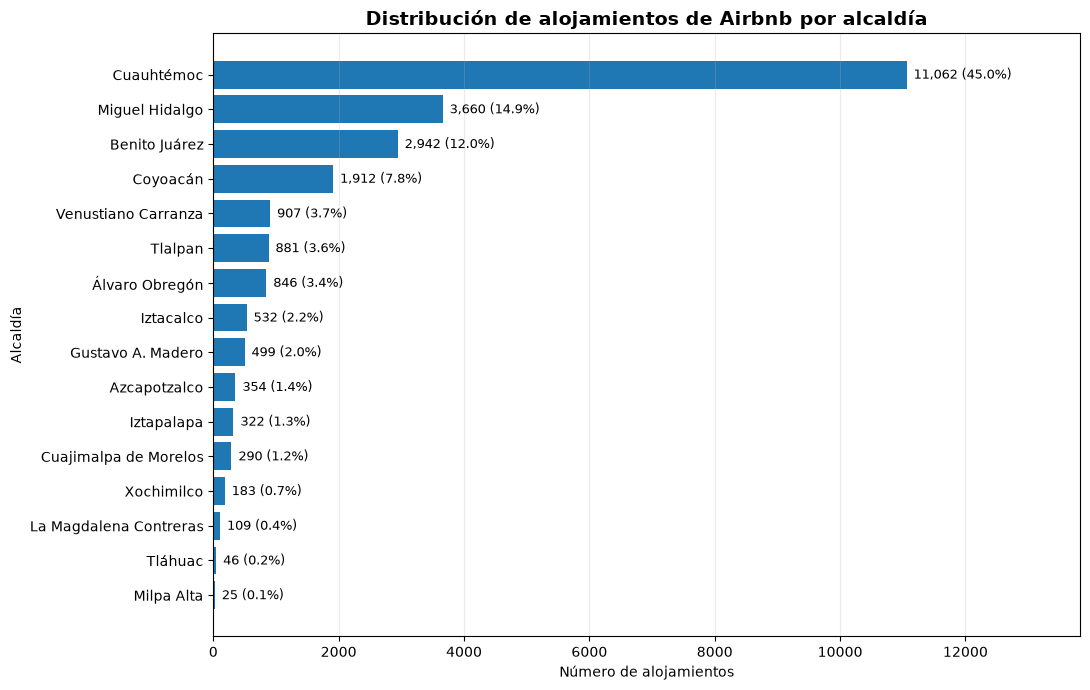


RESULTADO PRINCIPAL:
La alcaldía con más anuncios es Cuauhtémoc, con 11,062 anuncios (45.02% del total).
Las tres alcaldías con mayor frecuencia concentran el 71.89% de los anuncios.


In [57]:
print("PREGUNTA 1. DISTRIBUCIÓN GEOGRÁFICA")

datos_geo = df_viz.dropna(subset=["neighbourhood_cleansed"]).copy()
frecuencia_alcaldia = datos_geo["neighbourhood_cleansed"].value_counts()
porcentaje_alcaldia = frecuencia_alcaldia / frecuencia_alcaldia.sum() * 100

tabla_geografica = pd.DataFrame({
    "alojamientos": frecuencia_alcaldia,
    "porcentaje": porcentaje_alcaldia
})
print("\nDistribución por alcaldía:")
print(tabla_geografica.round(2).to_string())

# Gráfica de barras
fig, ax = plt.subplots(figsize=(11, 7))
frecuencia_ordenada = frecuencia_alcaldia.sort_values(ascending=True)
barras = ax.barh(
    frecuencia_ordenada.index.astype(str),
    frecuencia_ordenada.values
)

for barra, alcaldia in zip(barras, frecuencia_ordenada.index):
    valor = int(barra.get_width())
    porcentaje = porcentaje_alcaldia.loc[alcaldia]
    ax.text(
        valor + frecuencia_alcaldia.max() * 0.01,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:,} ({porcentaje:.1f}%)",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Distribución de alojamientos de Airbnb por alcaldía",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Número de alojamientos")
ax.set_ylabel("Alcaldía")
ax.set_xlim(0, frecuencia_alcaldia.max() * 1.25)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(carpeta_graficas / "01_distribucion_alcaldias.png", dpi=300, bbox_inches="tight")
plt.show()

top3_participacion = porcentaje_alcaldia.head(3).sum()
print("\nRESULTADO PRINCIPAL:")
print(
    f"La alcaldía con más anuncios es {frecuencia_alcaldia.index[0]}, "
    f"con {frecuencia_alcaldia.iloc[0]:,} anuncios "
    f"({porcentaje_alcaldia.iloc[0]:.2f}% del total)."
)
print(f"Las tres alcaldías con mayor frecuencia concentran el {top3_participacion:.2f}% de los anuncios.")


### **Pregunta 2. Diferencias en los precios** ¿Qué diferencias existen en los precios de los alojamientos según su ubicación y tipo de habitación?
Para contestar esta pregunta, realizamos un mapa de calor de precios medianos por alcaldía y tipo de habitación.
Las variables utilizadas para este análisis fueron:price, neighbourhood_cleansed y room_type.
Y las medidas: mediana, media, desviación estándar y cuartiles.

El mapa de calor compara simultáneamente las 16 alcaldías y los diferentes tipos de habitación, cada celda muestra el precio mediano por noche y el número de observaciones. Las combinaciones con menos de 10 anuncios se identifican como muestras pequeñas para evitar interpretaciones excesiva

PREGUNTA 2. PRECIOS

Precio por tipo de habitación (medidas descriptivas):
                     n   media  mediana  desviacion      q1      q3
room_type                                                          
Hotel room          46 3169.56  1946.13     3105.42 1320.25 3726.25
Entire home/apt  16588 2266.24  1784.90     1683.38 1296.32 2600.00
Private room      7738 1131.91   822.80     1153.73  600.00 1196.31
Shared room        198  687.88   400.00     1048.76  276.25  703.75

Precio por alcaldía:
                            n   media  mediana  desviacion      q1      q3
neighbourhood_cleansed                                                    
Miguel Hidalgo           3660 2313.59  1800.00     1798.98 1200.00 2782.00
Cuajimalpa de Morelos     290 2167.45  1738.35     1744.85 1039.50 2498.00
Cuauhtémoc              11062 2097.50  1654.34     1685.00 1124.96 2479.09
Álvaro Obregón            846 1670.06  1338.92     1466.37  826.30 1928.62
Benito Juárez            2942 1517.40  1217.2

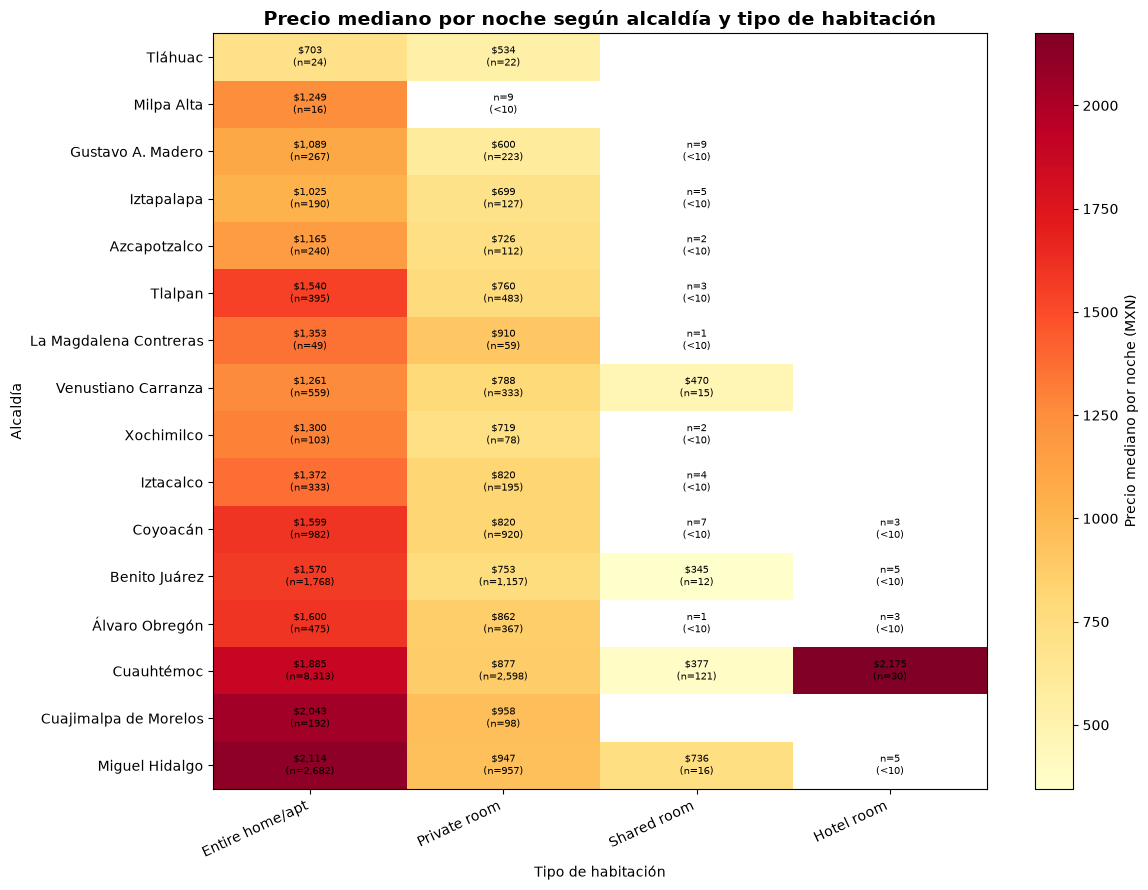


Prueba de Kruskal-Wallis: price según room_type
Grupos comparados: 4 | Observaciones: 24,570
Estadístico H: 7215.1882
Valor p: < 0.001
Épsilon cuadrada (tamaño de efecto aproximado): 0.2936
Interpretación: se encuentra evidencia estadística de que al menos un grupo difiere en su distribución. La prueba no identifica por sí sola qué pares de grupos son distintos.

Prueba de Kruskal-Wallis: price según neighbourhood_cleansed
Grupos comparados: 16 | Observaciones: 24,570
Estadístico H: 2371.6053
Valor p: < 0.001
Épsilon cuadrada (tamaño de efecto aproximado): 0.0960
Interpretación: se encuentra evidencia estadística de que al menos un grupo difiere en su distribución. La prueba no identifica por sí sola qué pares de grupos son distintos.


In [58]:
print("PREGUNTA 2. PRECIOS")

datos_precios = df_viz.dropna(
    subset=["price", "neighbourhood_cleansed", "room_type"]
).copy()
datos_precios = datos_precios[datos_precios["price"] > 0]

orden_room_type = [
    "Entire home/apt", "Private room", "Shared room", "Hotel room"
]
room_types_presentes = [
    x for x in orden_room_type if x in datos_precios["room_type"].dropna().unique()
]
room_types_presentes += [
    x for x in datos_precios["room_type"].dropna().unique()
    if x not in room_types_presentes
]

tabla_mediana_precio = datos_precios.pivot_table(
    index="neighbourhood_cleansed",
    columns="room_type",
    values="price",
    aggfunc="median"
).reindex(columns=room_types_presentes)

tabla_n_precio = datos_precios.pivot_table(
    index="neighbourhood_cleansed",
    columns="room_type",
    values="price",
    aggfunc="count",
    fill_value=0
).reindex(columns=room_types_presentes)

# Ordenar alcaldías por precio mediano general.
orden_alcaldias_precio = (
    datos_precios.groupby("neighbourhood_cleansed", observed=True)["price"]
    .median()
    .sort_values(ascending=True)
    .index
)
tabla_mediana_precio = tabla_mediana_precio.reindex(orden_alcaldias_precio)
tabla_n_precio = tabla_n_precio.reindex(
    index=orden_alcaldias_precio,
    columns=room_types_presentes
)

# No se muestran celdas con menos de 10 anuncios, ya que su mediana puede ser inestable y alterar resultados.
minimo_celda = 10
tabla_grafica_precio = tabla_mediana_precio.where(tabla_n_precio >= minimo_celda)

print("\nPrecio por tipo de habitación (medidas descriptivas):")
resumen_room_price = (
    datos_precios.groupby("room_type", observed=True)["price"]
    .agg(
        n="count",
        media="mean",
        mediana="median",
        desviacion="std",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
    .sort_values("mediana", ascending=False)
)
print(resumen_room_price.round(2).to_string())

print("\nPrecio por alcaldía:")
resumen_alcaldia_price = (
    datos_precios.groupby("neighbourhood_cleansed", observed=True)["price"]
    .agg(
        n="count",
        media="mean",
        mediana="median",
        desviacion="std",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
    .sort_values("mediana", ascending=False)
)
print(resumen_alcaldia_price.round(2).to_string())

# Mapa de calor de medianas por alcaldía y tipo de habitación.
fig, ax = plt.subplots(figsize=(12, 9))
matriz = np.ma.masked_invalid(tabla_grafica_precio.to_numpy(dtype=float))
imagen = ax.imshow(matriz, aspect="auto", cmap="YlOrRd")

ax.set_xticks(np.arange(len(room_types_presentes)))
ax.set_xticklabels(room_types_presentes, rotation=25, ha="right")
ax.set_yticks(np.arange(len(tabla_grafica_precio.index)))
ax.set_yticklabels(tabla_grafica_precio.index.astype(str))

for i, alcaldia in enumerate(tabla_grafica_precio.index):
    for j, room_type in enumerate(room_types_presentes):
        n = int(tabla_n_precio.loc[alcaldia, room_type])
        mediana = tabla_mediana_precio.loc[alcaldia, room_type]
        if n >= minimo_celda and pd.notna(mediana):
            etiqueta = f"${mediana:,.0f}\n(n={n:,})"
            ax.text(j, i, etiqueta, ha="center", va="center", fontsize=7)
        elif n > 0:
            ax.text(j, i, f"n={n}\n(<{minimo_celda})", ha="center", va="center", fontsize=7)

ax.set_title(
    "Precio mediano por noche según alcaldía y tipo de habitación",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Tipo de habitación")
ax.set_ylabel("Alcaldía")
barra_color = fig.colorbar(imagen, ax=ax)
barra_color.set_label("Precio mediano por noche (MXN)")
fig.tight_layout()
fig.savefig(carpeta_graficas / "02_precios_alcaldia_tipo_habitacion.png", dpi=300, bbox_inches="tight")
plt.show()

# Pruebas no paramétricas de diferencias entre grupos.
resultado_kw_room_price = reporte_kruskal(
    datos_precios, "room_type", "price", minimo_grupo=5
)
resultado_kw_alcaldia_price = reporte_kruskal(
    datos_precios, "neighbourhood_cleansed", "price", minimo_grupo=5
)


Para analizar cómo varían las tarifas según la ubicación y el nivel de privacidad del alojamiento, cruzamos las 16 alcaldías de la Ciudad de México con los cuatro tipos de habitación en un mapa de calor. Elegimos esta visualización porque permite comparar al mismo tiempo dos variables categóricas —ordenando las demarcaciones de menor a mayor tarifa— y utilizar una escala de color para identificar dónde se concentran los precios medianos más altos. Al igual que en el análisis anterior, incluimos el número de registros (n) en cada celda y omitimos el cálculo en combinaciones con menos de 10 anuncios para no sacar conclusiones engañosas a partir de muestras pequeñas.   

Al observar la gráfica, se distinguen dos patrones claros que marcan la estructura de precios en la ciudad:   

Brecha territorial entre alcaldías: Dentro de una misma categoría, la ubicación genera diferencias pronunciadas. En alojamientos completos (Entire home/apt), las tarifas medianas más altas se concentran en Miguel Hidalgo ($2,114 MXN), Cuajimalpa de Morelos ($2,043 MXN) y Cuauhtémoc ($1,885 MXN), mientras que en demarcaciones periféricas como Tláhuac ($703 MXN) o Iztapalapa ($1,025 MXN) el costo se reduce a menos de la mitad.   

Efecto del tipo de habitación: En prácticamente todas las alcaldías, rentar una propiedad completa cuesta más del doble que una habitación privada (Private room). De hecho, el peso de la ubicación es tal que una habitación privada en zonas de alta demanda como Cuajimalpa ($958 MXN) o Miguel Hidalgo ($947 MXN) alcanza tarifas muy cercanas a las de un departamento completo en alcaldías más alejadas del centro. Por su parte, las habitaciones de hotel (Hotel room) solo tienen presencia estadísticamente representativa en Cuauhtémoc, donde alcanzan la mediana más alta de toda la matriz ($2,175 MXN).   

Dado que los precios de alojamiento muestran una fuerte asimetría positiva y no cumplen con los supuestos de normalidad, incorporamos la prueba no paramétrica de Kruskal-Wallis para respaldar formalmente los patrones observados tanto entre los cuatro tipos de habitación como entre las 16 alcaldías. Al trabajar con rangos en lugar de promedios, esta prueba permite comprobar si las diferencias de precios medianos entre grupos son estadísticamente significativas y no producto del azar, lo que resulta clave para entender las dinámicas territoriales y de segmentación del mercado.

Por último, señalamos dos limitaciones importantes de este enfoque: primero, el análisis describe asociaciones entre ubicación, tipo de habitación y tarifa, pero no controla otras variables que también determinan el precio —como la colonia específica dentro de cada alcaldía, el tamaño del inmueble, las amenidades o la temporada—; y segundo, al ser una prueba global, Kruskal-Wallis confirma que existen diferencias significativas entre grupos, pero no identifica por sí sola qué pares específicos de alcaldías o categorías son los que más se distancian entre sí (lo cual requeriría pruebas post-hoc adicionales).

### **Pregunta 3. Características de los alojamientos** ¿Qué relación existe entre la capacidad de huéspedes, el tipo de propiedad y el precio por noche?
Se analizará el precio mediano según capacidad y tipo de propiedad por medio de un mapa de calor.
Las variables que se utilizarán son; accommodates, property_type y price y las medias; mediana, media, cuartiles y número de observaciones.
Para facilitar la lectura, las capacidades de 9 y 10 huéspedes se agrupan, al igual que las superiores a 10. Se muestran los seis tipos de propiedad más frecuentes y una categoría denominada "Otros".

PREGUNTA 3. CARACTERÍSTICAS DE LOS ALOJAMIENTOS

Precio por capacidad de huéspedes:
                    n   media  mediana  desviacion      q1      q3
grupo_capacidad                                                   
1                2167  780.69   624.00      782.32  457.00  870.32
2                9683 1407.93  1150.00     1083.81  779.00 1675.85
3                2437 1716.43  1500.00     1110.41 1100.00 2017.00
4                5410 2130.81  1800.00     1323.44 1320.00 2505.56
5                1402 2295.79  1904.75     1493.62 1405.00 2720.81
6                1888 2913.46  2368.30     1898.76 1669.89 3500.00
7                 311 3048.30  2603.00     1941.50 1793.66 3606.00
8                 521 3729.38  3191.00     2357.37 2139.28 4700.00
9-10              288 4372.68  3741.72     2762.93 2454.52 5446.25
11+               463 5892.30  5380.00     3247.21 3434.25 8000.00


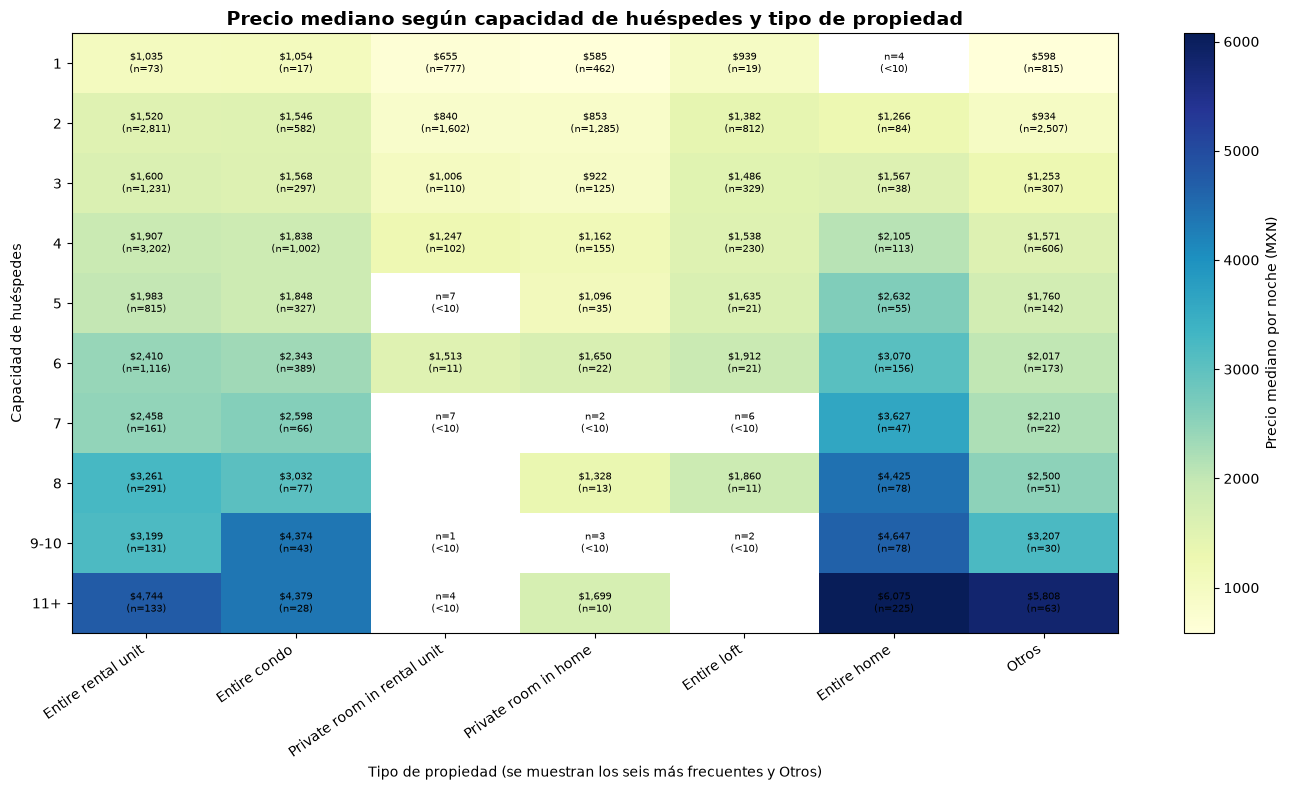


Asociación entre capacidad y precio (Spearman):
Rho de Spearman: 0.5730
Valor p: < 0.001
Interpretación: asociación monotónica positiva fuerte.

Prueba de Kruskal-Wallis: price según property_type
Grupos comparados: 6 | Observaciones: 19,854
Estadístico H: 6178.3672
Valor p: < 0.001
Épsilon cuadrada (tamaño de efecto aproximado): 0.3110
Interpretación: se encuentra evidencia estadística de que al menos un grupo difiere en su distribución. La prueba no identifica por sí sola qué pares de grupos son distintos.


In [59]:
print("PREGUNTA 3. CARACTERÍSTICAS DE LOS ALOJAMIENTOS")

datos_caracteristicas = df_viz.dropna(
    subset=["price", "accommodates", "property_type"]
).copy()
datos_caracteristicas = datos_caracteristicas[
    (datos_caracteristicas["price"] > 0) &
    (datos_caracteristicas["accommodates"] > 0)
]

# Agrupar capacidades altas para evitar celdas demasiado pequeñas.
def agrupar_capacidad(valor):
    valor = int(round(valor))
    if valor <= 8:
        return str(valor)
    elif valor <= 10:
        return "9-10"
    return "11+"

orden_capacidades = ["1", "2", "3", "4", "5", "6", "7", "8", "9-10", "11+"]
datos_caracteristicas["grupo_capacidad"] = (
    datos_caracteristicas["accommodates"].apply(agrupar_capacidad)
)

# Conservar los seis tipos de propiedad más frecuentes; el resto se agrupa.
top_propiedades = (
    datos_caracteristicas["property_type"]
    .value_counts()
    .head(6)
    .index
    .tolist()
)
datos_caracteristicas["tipo_propiedad_grafica"] = np.where(
    datos_caracteristicas["property_type"].isin(top_propiedades),
    datos_caracteristicas["property_type"],
    "Otros"
)
orden_propiedades = top_propiedades.copy()
if (datos_caracteristicas["tipo_propiedad_grafica"] == "Otros").any():
    orden_propiedades.append("Otros")

# Resumen estadístico de precio por capacidad.
resumen_capacidad = (
    datos_caracteristicas.groupby("grupo_capacidad", observed=True)["price"]
    .agg(
        n="count",
        media="mean",
        mediana="median",
        desviacion="std",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
    .reindex(orden_capacidades)
)
print("\nPrecio por capacidad de huéspedes:")
print(resumen_capacidad.round(2).to_string())

# Mediana por capacidad y tipo de propiedad.
tabla_capacidad_propiedad = datos_caracteristicas.pivot_table(
    index="grupo_capacidad",
    columns="tipo_propiedad_grafica",
    values="price",
    aggfunc="median"
).reindex(index=orden_capacidades, columns=orden_propiedades)

tabla_n_capacidad_propiedad = datos_caracteristicas.pivot_table(
    index="grupo_capacidad",
    columns="tipo_propiedad_grafica",
    values="price",
    aggfunc="count",
    fill_value=0
).reindex(index=orden_capacidades, columns=orden_propiedades)

minimo_celda_capacidad = 10
tabla_capacidad_visual = tabla_capacidad_propiedad.where(
    tabla_n_capacidad_propiedad >= minimo_celda_capacidad
)

fig, ax = plt.subplots(figsize=(14, 8))
matriz_capacidad = np.ma.masked_invalid(
    tabla_capacidad_visual.to_numpy(dtype=float)
)
imagen = ax.imshow(matriz_capacidad, aspect="auto", cmap="YlGnBu")

ax.set_xticks(np.arange(len(orden_propiedades)))
ax.set_xticklabels(orden_propiedades, rotation=35, ha="right")
ax.set_yticks(np.arange(len(orden_capacidades)))
ax.set_yticklabels(orden_capacidades)

for i, capacidad in enumerate(orden_capacidades):
    for j, propiedad in enumerate(orden_propiedades):
        n = int(tabla_n_capacidad_propiedad.loc[capacidad, propiedad])
        mediana = tabla_capacidad_propiedad.loc[capacidad, propiedad]
        if n >= minimo_celda_capacidad and pd.notna(mediana):
            ax.text(
                j, i,
                f"${mediana:,.0f}\n(n={n:,})",
                ha="center", va="center", fontsize=7
            )
        elif n > 0:
            ax.text(
                j, i, f"n={n}\n(<{minimo_celda_capacidad})",
                ha="center", va="center", fontsize=7
            )

ax.set_title(
    "Precio mediano según capacidad de huéspedes y tipo de propiedad",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Tipo de propiedad (se muestran los seis más frecuentes y Otros)")
ax.set_ylabel("Capacidad de huéspedes")
barra_color = fig.colorbar(imagen, ax=ax)
barra_color.set_label("Precio mediano por noche (MXN)")
fig.tight_layout()
fig.savefig(carpeta_graficas / "03_precio_capacidad_tipo_propiedad.png", dpi=300, bbox_inches="tight")
plt.show()

# Asociación monotónica entre capacidad y precio: Spearman.
rho, p_spearman = spearmanr(
    datos_caracteristicas["accommodates"],
    datos_caracteristicas["price"],
    nan_policy="omit"
)
print("\nAsociación entre capacidad y precio (Spearman):")
print(f"Rho de Spearman: {rho:.4f}")
print(f"Valor p: {'< 0.001' if p_spearman < 0.001 else f'{p_spearman:.4f}'}")

if abs(rho) < 0.10:
    fuerza = "muy débil"
elif abs(rho) < 0.30:
    fuerza = "débil"
elif abs(rho) < 0.50:
    fuerza = "moderada"
else:
    fuerza = "fuerte"

direccion = "positiva" if rho > 0 else "negativa"
print(f"Interpretación: asociación monotónica {direccion} {fuerza}.")

# Diferencias de precio entre los tipos de propiedad más frecuentes.
datos_top_propiedades = datos_caracteristicas[
    datos_caracteristicas["property_type"].isin(top_propiedades)
]
resultado_kw_propiedad = reporte_kruskal(
    datos_top_propiedades, "property_type", "price", minimo_grupo=5
)





Para entender cómo influyen el tamaño del alojamiento y el tipo de propiedad en el precio por noche, cruzamos ambas variables en un mapa de calor. Elegimos esta visualización porque permite leer de un vistazo dos factores al mismo tiempo —los tipos de propiedad más comunes frente a la capacidad de huéspedes— usando la intensidad del color para mostrar dónde se concentran las tarifas medianas más altas.

Además, decidimos incluir el número de anuncios (n) dentro de cada recuadro y dejar en blanco las combinaciones con menos de 10 registros para no sacar conclusiones engañosas a partir de pocos datos.

Al observar la gráfica, salta a la vista un comportamiento escalonado muy claro: dentro de un mismo tipo de propiedad, entre más huéspedes caben, más sube el precio. Por ejemplo, en un departamento completo (Entire rental unit), la tarifa mediana arranca en $1,035 MXN para una persona, sube a $1,907 MXN cuando es para cuatro, y llega hasta los $4,744 MXN en espacios para 11 o más huéspedes.

Al mismo tiempo, si comparamos alojamientos con la misma capacidad, rentar una propiedad completa (casa, departamento o condominio) cuesta prácticamente el doble que quedarse en una habitación privada.

Como los precios en este mercado tienen un fuerte sesgo hacia valores altos y no siguen una distribución normal, respaldamos lo que muestra la gráfica utilizando pruebas estadísticas no paramétricas, que trabajan con rangos y no se dejan distorsionar por los precios extremos:Correlación de Spearman (Capacidad vs. Precio): La elegimos en lugar de la correlación tradicional de Pearson porque mide si dos variables crecen juntas sin exigir que lo hagan en una línea recta perfecta.

El resultado ($\rho = 0.5731, p < 0.001$) confirma una relación positiva fuerte: conforme aumenta la capacidad de huéspedes, el precio por noche sube de manera constante y estadísticamente significativa.

Prueba de Kruskal-Wallis (Tipo de propiedad vs. Precio): Funcionó como nuestra alternativa al ANOVA para comparar al mismo tiempo las tarifas de los seis tipos de propiedad principales ($n = 19,852$). El resultado ($H = 6,178.10, p < 0.001$) demuestra que existen diferencias claras en los precios según el formato del inmueble. Más allá de confirmar que son distintos, el tamaño del efecto ($\varepsilon^2 = 0.3110$) revela un impacto grande, indicándonos que el tipo de propiedad explica por sí solo cerca del 31.1 % de la variación en los rangos de precios. Si bien esta prueba global nos dice que los grupos difieren entre sí, haría falta un análisis post-hoc (como la prueba de Dunn) para señalar exactamente qué pares específicos son los que más se distancian.

En pocas palabras, tanto la gráfica como las pruebas estadísticas dejan claro que el precio de un Airbnb en la Ciudad de México está estrechamente asociado con la combinación entre cuántas personas puede recibir y qué tanta privacidad ofrece el tipo de inmueble. No obstante, es importante señalar que la relación observada entre capacidad y precio es meramente asociativa y no implica causalidad; además, al tratarse de un análisis exploratorio bivariado, no se están controlando otras variables del inmueble —como su ubicación exacta, amenidades, antigüedad o estado de conservación— que también influyen de manera determinante en la fijación de tarifas.

### **Pregunta 4. Características de los Concentración de anfitriones.** ¿En qué medida se concentra la oferta de alojamientos entre anfitriones que administran múltiples anuncios?





Las tablas y la gráfica a continuación permiten estudiar la concentración de alojamientos entre anfitriones, es decir, si los anuncios están distribuidos principalmente entre anfitriones con una sola oferta individual o si una proporción considerable está administrada por anfitriones con múltiples propiedades.

Para visualizar esta distribución se optó por un gráfico de barras verticales, ya que es la herramienta más efectiva para comparar magnitudes exactas entre categorías discretas y ordenadas según el tamaño del portafolio del anfitrión (1 anuncio hasta 11+ anuncios). Al incluir etiquetas numéricas sobre cada barra y eliminar elementos visuales innecesarios, el gráfico permite comparar de forma directa el peso real que tiene cada segmento sobre el total de la oferta (df_final).

Los resultados revelan una concentración importante del mercado: aunque la mayoría de los anfitriones de Airbnb (69 %) tiene un solo anuncio, estos representan únicamente el 33.9 % del total de alojamientos. En contraste, los anfitriones con múltiples propiedades (2 o más anuncios) concentran en conjunto el 66.1 % restante de la oferta. Destaca especialmente el segmento de grandes administradores (6–10 anuncios con 12.3 % y 11+ anuncios con 20.4 %), quienes representan apenas el 5 % de los anfitriones, pero controlan prácticamente un tercio (32.7 %) de todos los espacios publicados en la ciudad.   Además, al analizar a los anfitriones con más anuncios, se observan diferencias en los precios y en la cantidad de alcaldías donde operan.

Algunos concentran sus propiedades en una sola alcaldía, mientras que otros se distribuyen en varias. Esto sugiere que existen distintas formas de administrar los alojamientos, aunque sería necesario realizar análisis adicionales para determinar si estas diferencias se relacionan con los precios o con la ubicación.

Total de anfitriones únicos: 12,001
Anfitriones con 1 solo anuncio: 8,326 (69.4%)
Multi-anfitriones (>=2 anuncios): 3,675 (30.6%) -> concentran 16,244 anuncios (66.1% del total)

--- TOP 10 ANFITRIONES POR NÚMERO DE ANUNCIOS (df_final) ---


,n_anuncios,alcaldias_distintas,mediana_precio_host
host_id,,,
333035396,154,5,2116.25
671935678,148,2,2174.04
10764020,105,3,3615.00
91265490,104,2,1551.00
302431514,82,4,2295.25
23468816,82,3,3317.48
447270714,78,3,1373.00
348389387,68,1,650.00
104953556,68,3,4856.21


,n_anfitriones,total_anuncios,pct_anfitriones,pct_anuncios
n_anuncios,,,,
1 anuncio,8326,8326,0.69,0.34
2 anuncios,1709,3418,0.14,0.14
3–5 anuncios,1328,4791,0.11,0.20
6+ anuncios,638,8035,0.05,0.33


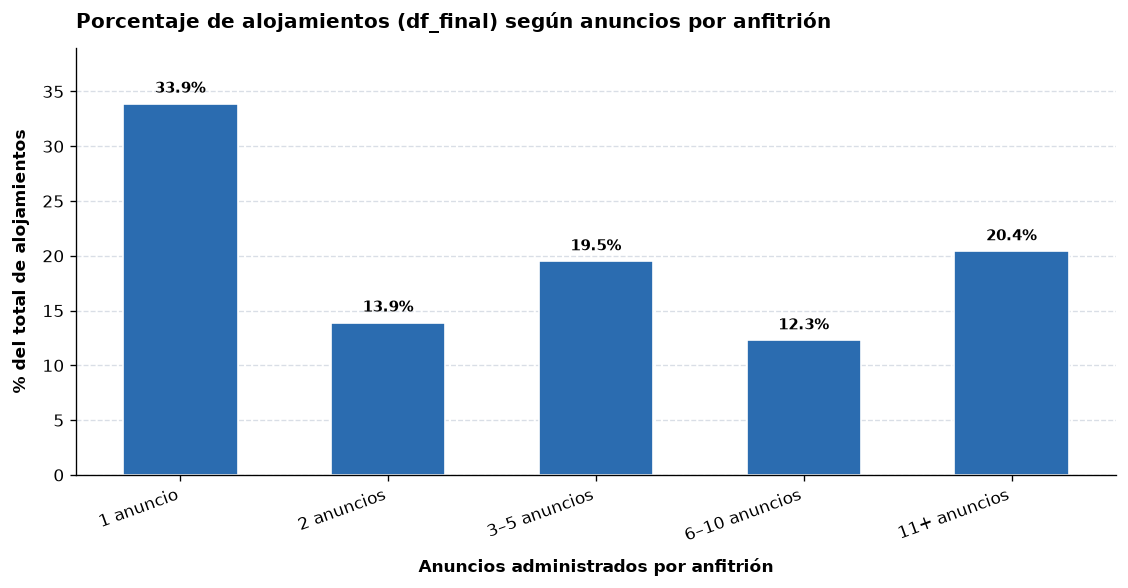

In [60]:
# 4 Anuncios por anfitrión en df_final


anuncios_por_host = (
    df_final.groupby('host_id')
    .agg(
        n_anuncios=('id', 'nunique'),
        alcaldias_distintas=('neighbourhood_cleansed', 'nunique'),
        mediana_precio_host=('price', 'median')
    )
    .sort_values('n_anuncios', ascending=False)
)

total_anuncios = len(df_final)
total_hosts = len(anuncios_por_host)
multi_hosts = anuncios_por_host[anuncios_por_host['n_anuncios'] >= 2]
anuncios_multi = multi_hosts['n_anuncios'].sum()

print(f"Total de anfitriones únicos: {total_hosts:,}")
print(f"Anfitriones con 1 solo anuncio: {(anuncios_por_host['n_anuncios'] == 1).sum():,} "
      f"({(anuncios_por_host['n_anuncios'] == 1).mean():.1%})")
print(f"Multi-anfitriones (>=2 anuncios): {len(multi_hosts):,} ({len(multi_hosts)/total_hosts:.1%}) "
      f"-> concentran {anuncios_multi:,} anuncios ({anuncios_multi/total_anuncios:.1%} del total)")

print("\n--- TOP 10 ANFITRIONES POR NÚMERO DE ANUNCIOS (df_final) ---")
display(anuncios_por_host.head(10).round(2))

# 4B. Segmentación de anfitriones por tamaño de portafolio
segmento_host = pd.cut(
    anuncios_por_host['n_anuncios'],
    bins=[0, 1, 2, 5, np.inf],
    labels=['1 anuncio', '2 anuncios', '3–5 anuncios', '6+ anuncios']
)
resumen_segmento = (
    anuncios_por_host.groupby(segmento_host, observed=False)
    .agg(
        n_anfitriones=('n_anuncios', 'count'),
        total_anuncios=('n_anuncios', 'sum')
    )
    .assign(
        pct_anfitriones=lambda d: d['n_anfitriones'] / d['n_anfitriones'].sum(),
        pct_anuncios=lambda d: d['total_anuncios'] / d['total_anuncios'].sum()
    )
)
display(resumen_segmento.round(3))

# --- Pregunta 4: % de alojamientos según anuncios administrados por anfitrión ---
conteo_por_host = df_final.groupby('host_id')['id'].transform('count')
tramos_anuncios = pd.cut(
    conteo_por_host,
    bins=[0, 1, 2, 5, 10, np.inf],
    labels=['1 anuncio', '2 anuncios', '3–5 anuncios', '6–10 anuncios', '11+ anuncios']
)
pct_oferta = tramos_anuncios.value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(9.5, 5), dpi=120)
barras = ax.bar(pct_oferta.index.astype(str), pct_oferta.values, width=0.55, color='#2b6cb0', edgecolor='white')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle='--', alpha=0.35, color='#94a3b8')
ax.set_ylim(0, pct_oferta.max() * 1.15)

ax.set_title(
    'Porcentaje de alojamientos (df_final) según anuncios por anfitrión',
    fontsize=12,
    fontweight='bold',
    loc='left',
    pad=12
)
ax.set_xlabel('Anuncios administrados por anfitrión', fontsize=10, fontweight='bold', labelpad=8)
ax.set_ylabel('% del total de alojamientos', fontsize=10, fontweight='bold', labelpad=8)
plt.xticks(rotation=20, ha='right')

for idx, val in enumerate(pct_oferta):
    ax.text(idx, val + pct_oferta.max() * 0.02, f'{val:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

fig.tight_layout()
plt.show()

### **Pregunta 5. Calificaciones:** ¿Qué diferencias existen en las calificaciones de los alojamientos según su tipo de habitación?

Para esta pregunta se escogió un box plot porque nos deja ver de manera rápida la mediana, qué tan apretado o abierto está el rango intercuartílico y dónde caen las calificaciones bajas entre los tipos de habitación en la misma escala, algo que funciona muy bien cuando las puntuaciones se concentran arriba y tienen algunos valores bajos aislados. Eso sí, como no enseña ni la forma exacta de la distribución ni cuántos anuncios tienen reseñas o se quedan en NaN, conviene leerlo junto con la tabla de mediana.

El gráfico a continuación muestra la distribución de review_scores_rating (escala de 1 a 5) exclusivamente en anuncios con evaluación (df_final). En las cuatro categorías, las calificaciones se concentran en valores altos (cerca de 4.75–5.0) con asimetría negativa (cola larga hacia calificaciones bajas).


Entire home/apt (n = 15,123): Es la categoría con mayor número de registros y presenta la mediana más alta, ligeramente superior a 4.8. Además, sus calificaciones muestran una menor dispersión, lo que se refleja en una caja más compacta. Sin embargo, también concentra numerosos valores atípicos en el extremo inferior, con calificaciones que llegan hasta 1.0.

Private room (n = 6,376): Es la segunda categoría con más registros y mantiene una mediana muy similar a la de Entire home/apt (cerca de 4.8). No obstante, presenta una dispersión ligeramente mayor, tanto en la caja como en el bigote inferior, que se sitúa aproximadamente entre 4.15 y 4.2. Al igual que la categoría anterior, registra varios valores atípicos con calificaciones de hasta 1.0.

Hotel room (n = 40): Esta categoría cuenta con una cantidad considerablemente menor de observaciones. Su mediana se encuentra alrededor de 4.8 y el bigote inferior cerca de 4.0, además de presentar un valor atípico aislado próximo a 3.3. Debido al reducido tamaño de la muestra, sus resultados deben interpretarse con cautela y no son directamente comparables con los de las categorías principales.

Shared room (n = 149): Es la categoría que presenta la mediana más baja, aunque se mantiene ligeramente por debajo de 4.8. También muestra una mayor amplitud en su caja, lo que sugiere una variación más amplia en las calificaciones. Asimismo, presenta valores atípicos que llegan hasta 1.0.

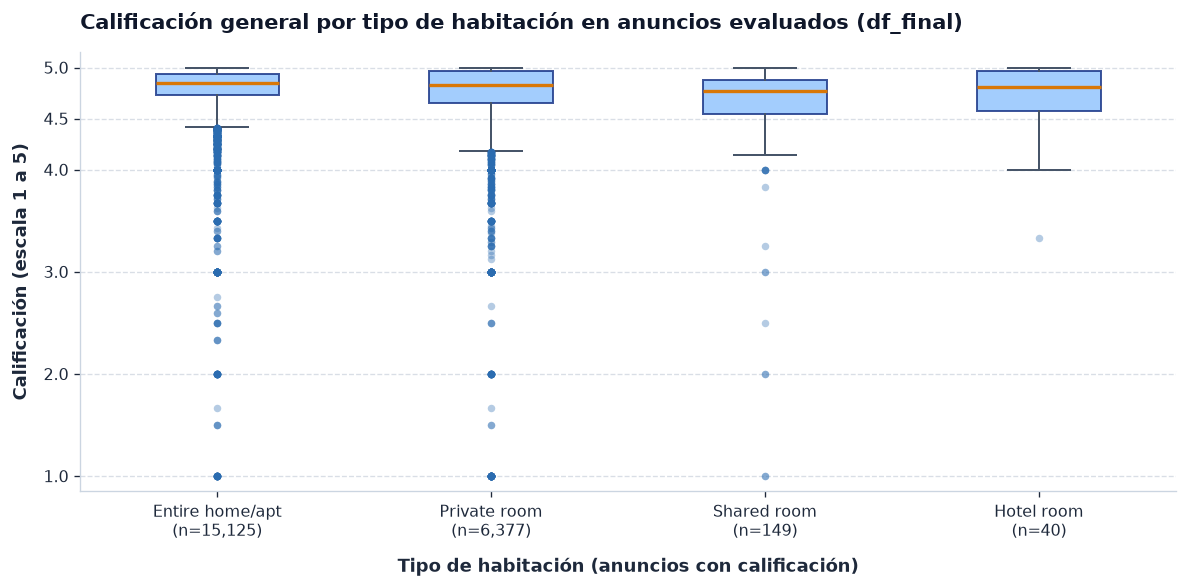

In [61]:
# ------ 5 -------- Box Plot

rooms_cal = df_final['room_type'].dropna().unique()


datos_cal = [
    df_final.loc[
        (df_final['room_type'] == r) & (df_final['review_scores_rating'].notna()),
        'review_scores_rating'
    ].to_numpy()
    for r in rooms_cal
]

etiquetas_x = [f"{r}\n(n={len(d):,})" for r, d in zip(rooms_cal, datos_cal)]
datos_cal = [
    df_final.loc[
        (df_final['room_type'] == r) & (df_final['review_scores_rating'].notna()),
        'review_scores_rating'
    ].to_numpy()
    for r in rooms_cal
]

etiquetas_x = [f"{r}\n(n={len(d):,})" for r, d in zip(rooms_cal, datos_cal)]

fig, ax = plt.subplots(figsize=(10, 5), dpi=120)

bp = ax.boxplot(
    datos_cal,
    tick_labels=etiquetas_x,
    patch_artist=True,
    widths=0.45,
    medianprops=dict(color='#d97706', linewidth=2),
    whiskerprops=dict(color='#475569', linewidth=1.2),
    capprops=dict(color='#475569', linewidth=1.2),
    flierprops=dict(
        marker='o',
        markersize=4.5,
        markerfacecolor='#2b6cb0',
        markeredgecolor='none',
        alpha=0.35
    )
)

for box in bp['boxes']:
    box.set_facecolor('#93c5fd')
    box.set_edgecolor('#1e3a8a')
    box.set_linewidth(1.2)
    box.set_alpha(0.85)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#cbd5e1')
ax.spines['bottom'].set_color('#cbd5e1')
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle='--', alpha=0.35, color='#94a3b8')

ax.set_ylim(0.85, 5.15)
ax.set_yticks([1, 2, 3, 4, 4.5, 5])
ax.set_xlabel('Tipo de habitación (anuncios con calificación)', fontsize=10.5, fontweight='bold', color='#1e293b', labelpad=10)
ax.set_ylabel('Calificación (escala 1 a 5)', fontsize=10.5, fontweight='bold', color='#1e293b', labelpad=8)
ax.set_title(
    'Calificación general por tipo de habitación en anuncios evaluados (df_final)',
    fontsize=12.5,
    fontweight='bold',
    color='#0f172a',
    loc='left',
    pad=14
)

ax.tick_params(axis='both', labelsize=9.5, colors='#1e293b')
fig.tight_layout()
plt.show()

## Conclusiones Generales

A partir del análisis exploratorio y estadístico realizado sobre **24,567 anuncios depurados** (`df_final`) de Airbnb en la Ciudad de México, se cumple el objetivo de caracterizar la dinámica espacial, económica y operativa de la plataforma, evidenciando un mercado con marcados contrastes territoriales y un alto grado de concentración comercial:

1. **Centralización geográfica y brecha de precios:** La oferta y las tarifas más elevadas se concentran en el corredor centro-poniente de la ciudad (especialmente en **Cuauhtémoc**, **Miguel Hidalgo** y **Cuajimalpa de Morelos**), donde la mediana de un alojamiento completo ronda entre los **$1,885 y $2,114 MXN** por noche. En contraste, las alcaldías periféricas presentan una oferta mucho menor y tarifas medianas que caen por debajo de la mitad, como ocurre en **Tláhuac** (**$703 MXN**) o **Iztapalapa** (**$1,025 MXN**).
2. **Privacidad, tamaño y formato como motores de la tarifa:** El precio por noche no responde a un único factor, sino a la interacción entre ubicación, privacidad y capacidad. Los alojamientos completos cuestan más del doble que las habitaciones privadas dentro de una misma alcaldía[cite: 3], mientras que la capacidad de huéspedes mantiene una asociación monotónica positiva fuerte con el precio ($\rho = 0.5731, p < 0.001$), escalando de forma consistente desde espacios individuales hasta propiedades de gran formato (`11+` huéspedes). Las pruebas no paramétricas de **Kruskal-Wallis** confirman que las diferencias de distribución de precios tanto entre alcaldías como entre tipos de propiedad y habitación son estadísticamente significativas ($p < 0.001$).
3. **Profesionalización de la oferta (concentración de anfitriones):** Si bien la mayoría de los usuarios registrados en la plataforma (**69 %**) son anfitriones individuales con un solo anuncio, estos apenas representan el **33.9 %** de los alojamientos disponibles. En cambio, la minoría de anfitriones con múltiples propiedades (**31 %**) controla dos terceras partes (**66.1 %**) de toda la oferta en la ciudad. Particularmente, el **5 %** de los anfitriones con 6 o más anuncios concentra el **32.7 %** del mercado, lo que demuestra que una proporción sustancial de la plataforma opera bajo esquemas de administración profesional o inmobiliaria más que de economía colaborativa ocasional.
4. **Percepción de calidad (calificaciones):** Las puntuaciones otorgadas por los huéspedes muestran una distribución altamente concentrada en valores elevados a lo largo de los distintos tipos de habitación, lo que sugiere estándares de satisfacción homogéneos en los anuncios activos, aunque con diferencias en la frecuencia de reseñas según la rotación de cada formato.

### Alcances y limitaciones metodológicas
El uso de medidas robustas (medianas y rangos intercuartílicos) junto con pruebas no paramétricas (Spearman y Kruskal-Wallis) permitió analizar con rigor un mercado caracterizado por una fuerte asimetría positiva y valores atípicos sin depender de supuestos de normalidad. No obstante, al tratarse de un estudio observacional y exploratorio basado en una fotografía estática de la oferta publicada, los hallazgos describen **asociaciones estadísticas y no relaciones de causalidad**. Asimismo, el análisis no controla variables granulares —como la colonia específica dentro de cada alcaldía, las amenidades del inmueble, la estacionalidad o las tasas reales de ocupación—, factores que representan líneas naturales de profundización para futuras investigaciones mediante modelos multivariados.